# Exploratory data analysis and results

OHLCV data comes from the Binance public API via `ccxt` (educational use only). This notebook answers three questions for the report:

1. How are crypto returns distributed?
2. Are returns autocorrelated, i.e. is direction predictable at all?
3. How do trading fees affect the strategy, and how does v2 address that?

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cq.data import load_ohlcv
from cq.features import build_features
from cq.labels import make_dataset
from cq.pipeline import load_config, period_summary, run_all

if Path.cwd().name == "notebooks":
    os.chdir("..")  # config.yaml, data/ and results/ are resolved from the repository root
cfg = load_config()
plt.rcParams["figure.figsize"] = (11, 4)
data = {s: load_ohlcv(s, "1d", cfg["since"], cfg["exchange"]) for s in cfg["symbols"]}
{s: (d.index[0].date(), d.index[-1].date(), len(d)) for s, d in data.items()}

{'BTC/USDT': (datetime.date(2019, 1, 1), datetime.date(2026, 11, 11), 2872),
 'ETH/USDT': (datetime.date(2019, 1, 1), datetime.date(2026, 11, 11), 2872),
 'SOL/USDT': (datetime.date(2020, 8, 11), datetime.date(2026, 11, 11), 2284)}

## 1. Prices and return distribution

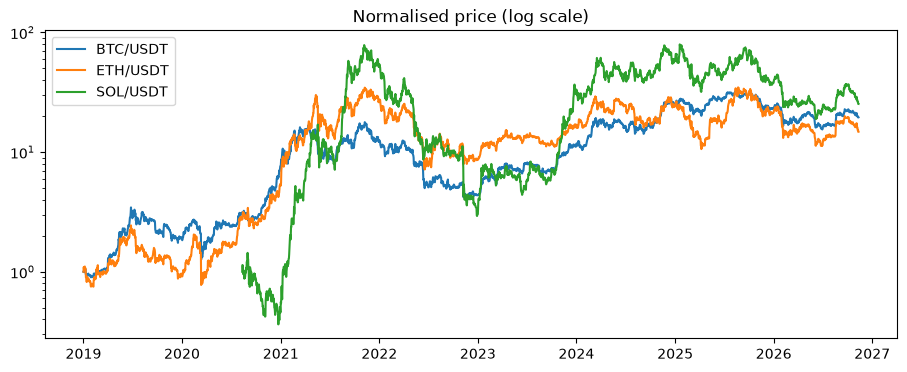

In [2]:
fig, ax = plt.subplots()
for s, d in data.items():
    ax.plot(d["close"] / d["close"].iloc[0], label=s)
ax.set_yscale("log")
ax.set_title("Normalised price (log scale)")
ax.legend()
plt.show()

In [3]:
rets = pd.DataFrame({s: np.log(d["close"]).diff() for s, d in data.items()})
stats = pd.DataFrame(
    {
        "mean": rets.mean(),
        "std": rets.std(),
        "skew": rets.skew(),
        "kurtosis": rets.kurt(),
        "up_rate": (rets > 0)[rets.notna()].mean(),
    }
)
stats.round(4)

,mean,std,skew,kurtosis,up_rate
BTC/USDT,0.0010,0.0324,-1.2646,23.4285,0.509579
ETH/USDT,0.0009,0.0426,-1.0492,16.8174,0.514803
SOL/USDT,0.0014,0.0590,-0.2067,8.5349,0.496277


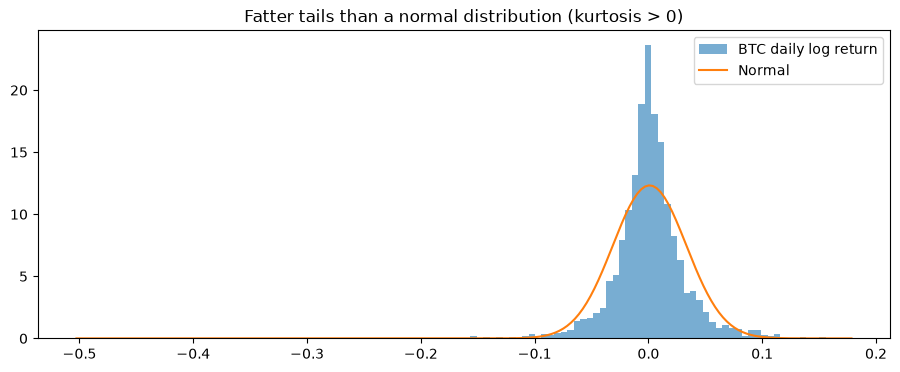

In [4]:
r = rets["BTC/USDT"].dropna()
x = np.linspace(r.min(), r.max(), 200)
normal_pdf = np.exp(-((x - r.mean()) ** 2) / (2 * r.var())) / np.sqrt(2 * np.pi * r.var())
plt.hist(r, bins=120, density=True, alpha=0.6, label="BTC daily log return")
plt.plot(x, normal_pdf, label="Normal")
plt.legend()
plt.title("Fatter tails than a normal distribution (kurtosis > 0)")
plt.show()

**Observation:** about 50% of days are up, so the classification problem is nearly balanced and 50% accuracy is chance level. High kurtosis means extreme moves are frequent, which is why risky strategies suffer deep drawdowns.

## 2. Autocorrelation

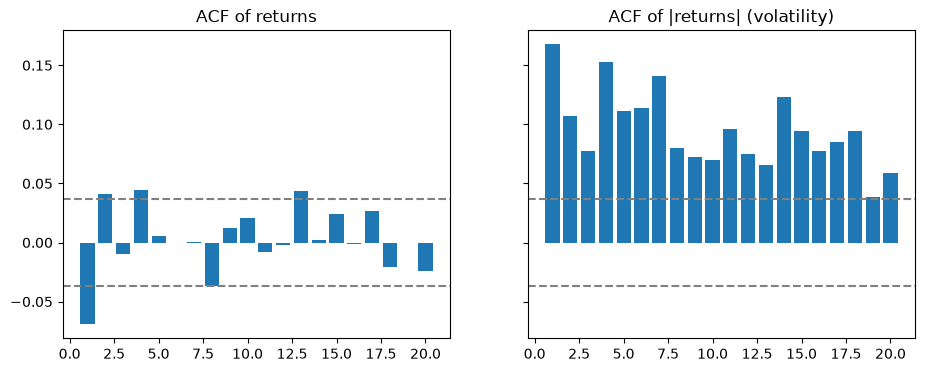

In [5]:
def acf(s, lags=20):
    return [s.autocorr(k) for k in range(1, lags + 1)]


fig, axes = plt.subplots(1, 2, sharey=True)
conf = 1.96 / np.sqrt(len(r))
panels = ((axes[0], r, "ACF of returns"), (axes[1], r.abs(), "ACF of |returns| (volatility)"))
for ax, series, title in panels:
    ax.bar(range(1, 21), acf(series))
    ax.axhline(conf, ls="--", c="gray")
    ax.axhline(-conf, ls="--", c="gray")
    ax.set_title(title)
plt.show()

**Observation:** return autocorrelation stays mostly inside the confidence band, so direction is very hard to predict (close to the efficient-market hypothesis). Absolute returns, however, are clearly autocorrelated (volatility clustering), so volatility features help identify turbulent regimes.

## 3. Feature–label correlation

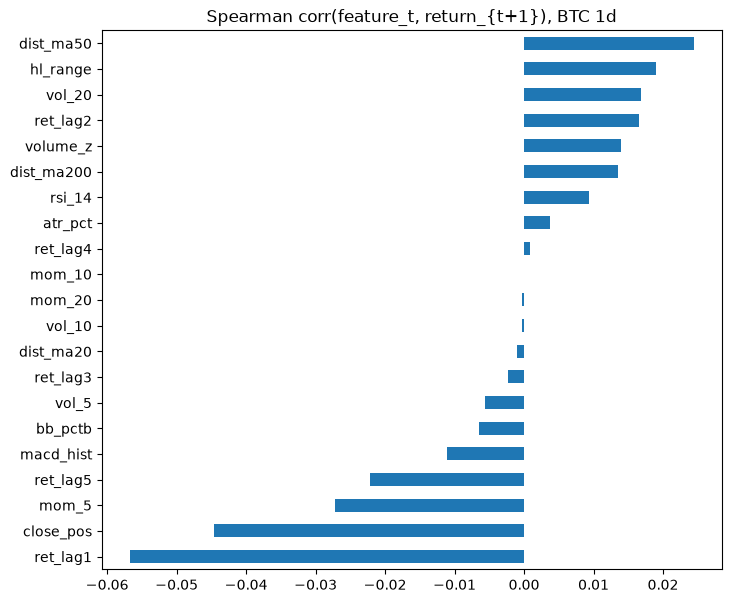

In [6]:
d = data["BTC/USDT"]
X, y, fwd = make_dataset(build_features(d), d["close"])
corr = X.corrwith(fwd, method="spearman").sort_values()
corr.plot.barh(figsize=(8, 7), title="Spearman corr(feature_t, return_{t+1}), BTC 1d")
plt.show()

## 4. Fee impact: v1 (original) vs v2 (improved)

**v1**: 1-bar label, enter when p > 0.5, exit when p < 0.5. **v2**: 3-bar label (less noise) plus a ±0.05 hysteresis band (enter when p > 0.55, exit when p < 0.45). The v2 configuration was selected using only data before 2025.

In [7]:
versions = {"v1": dict(horizon=1, band=0.0), "v2": dict(horizon=3, band=0.05)}
cols = ["total_return", "sharpe", "max_drawdown", "n_trades"]
rows = []
for name, kw in versions.items():
    for fee in [0.0, 0.0002, 0.0005, 0.001]:
        t, _ = run_all("BTC/USDT", "4h", cfg, fee=fee, models=["lightgbm"], **kw)
        rows.append({"version": name, "fee_%": fee * 100, **t.loc["lightgbm", cols].to_dict()})
fee_tbl = pd.DataFrame(rows).set_index(["version", "fee_%"])
fee_tbl.round(3)

total_return  sharpe  max_drawdown  n_trades
version fee_%                                              
v1      0.00         17.649   1.404        -0.525    5955.0
        0.02          4.667   0.919        -0.585    5955.0
        0.05         -0.051   0.192        -0.665    5955.0
        0.10         -0.952  -1.020        -0.975    5955.0
v2      0.00          9.025   1.067        -0.487     907.0
        0.02          7.361   1.002        -0.501     907.0
        0.05          5.369   0.905        -0.523     907.0
        0.10          3.045   0.742        -0.567     907.0

v1 trades about 6,000 times and only profits when fees are near zero. v2 trades roughly 6× less and survives realistic fees.

## 5. Design vs holdout (default v2 configuration)

In [8]:
hs = cfg["holdout_start"]
metric_cols = ["total_return", "sharpe", "max_drawdown"]
res = []
for tf in cfg["timeframes"]:
    for s in cfg["symbols"]:
        _, exps = run_all(s, tf, cfg, models=["lightgbm"])
        bts = {m: e.bt for m, e in exps.items()}
        for period, kw in (("design", dict(end=hs)), ("holdout", dict(start=hs))):
            ps = period_summary(bts, tf, **kw)
            for m in ps.index:
                res.append({"pair": f"{s} {tf}", "period": period, "model": m, **ps.loc[m, metric_cols].to_dict()})
res = pd.DataFrame(res)
res.pivot_table(index=["period", "pair"], columns="model", values=["sharpe", "max_drawdown"]).round(2)

max_drawdown                sharpe         
model               buy_and_hold lightgbm buy_and_hold lightgbm
period  pair                                                   
design  BTC/USDT 1d        -0.77    -0.69         0.84     0.46
        BTC/USDT 4h        -0.77    -0.57         0.70     1.05
        ETH/USDT 1d        -0.79    -0.72         0.57     0.10
        ETH/USDT 4h        -0.81    -0.62         0.63     0.72
        SOL/USDT 1d        -0.43    -0.35         1.79     1.55
        SOL/USDT 4h        -0.76    -0.62         1.27     1.31
holdout BTC/USDT 1d        -0.53    -0.54        -0.07    -0.00
        BTC/USDT 4h        -0.53    -0.48        -0.08    -0.12
        ETH/USDT 1d        -0.68    -0.44        -0.02     0.66
        ETH/USDT 4h        -0.68    -0.54        -0.07     0.54
        SOL/USDT 1d        -0.76    -0.65        -0.19    -0.34
        SOL/USDT 4h        -0.78    -0.41        -0.22    -0.15

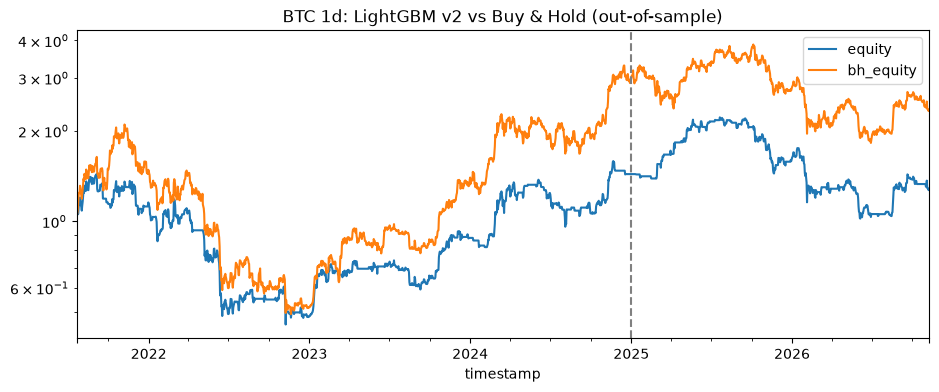

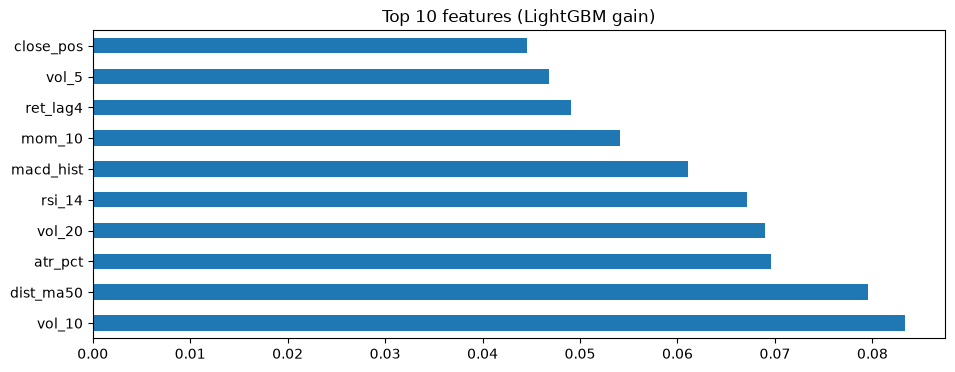

In [9]:
t1d, exps = run_all("BTC/USDT", "1d", cfg)
bt = exps["lightgbm"].bt
ax = bt[["equity", "bh_equity"]].plot(logy=True, title="BTC 1d: LightGBM v2 vs Buy & Hold (out-of-sample)")
ax.axvline(pd.Timestamp(hs, tz="UTC"), ls="--", c="gray")
plt.show()
exps["lightgbm"].wf.importance.head(10).plot.barh(title="Top 10 features (LightGBM gain)")
plt.show()

## Conclusions

- Out-of-sample accuracy is only about 50–55% and AUC about 0.50–0.56: there is a signal, but it is weak, as expected in a highly competitive market.
- **Transaction costs are decisive.** v1 has a real signal on 4h bars, but thousands of trades wipe out the capital. A less noisy label (horizon 3) and a hysteresis band cut trading 5–10× and lift the average design-period Sharpe from 0.28 to 0.87.
- On the **holdout** period 2025–2026 (a falling market, Buy & Hold Sharpe ≈ −0.1), LightGBM v2 reaches a Sharpe of +0.10, beats Buy & Hold on 4 of 6 pairs, and has an average max drawdown of −51% vs −66%.
- In the strong bull market of the design period, v2 still does not consistently beat Buy & Hold: staying out of the market misses part of the uptrend. The model's main value is **risk reduction** in downturns, not higher returns.
- Limitations: a short holdout (≈ 22 months) and only 3 highly correlated coins, so the evidence for a durable edge is not yet sufficient.